[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB14a_silencing_a_hub.ipynb)

# Day 2 · Chapter 5 · Notebook 14a — Silencing a hub (exercise)

Take the Hopf model of NB10, push one region **far below its bifurcation** ($a=-5$) so that it damps whatever it
receives, and measure how the FC of the **rest** of the brain changes. Compare a hub with a weakly connected region.
This is the "local silencing" experiment of the slides, done in the model. In pairs, about 25 minutes; solutions at the end.

<details><summary>Why a = −5 means "silenced"</summary>

In the Hopf model $a$ is the distance to the bifurcation. A region with a very negative $a$ forgets any input almost at
once: it no longer amplifies or relays activity. (In the neural-mass model of NB11 the corresponding knob is the
excitability $\eta$; we use it in NB14c.) All other regions stay at the working point of NB13b, $a=-0.1$, $G=2$.
</details>

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
labels = [l.replace("7Networks_", "") for l in labels]
net = np.array([l.split("_")[1] for l in labels])
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]

def show_matrix(ax, M, title, vmax=1.0):                           # matrix with regions grouped by network
    im = ax.imshow(M[np.ix_(order, order)], cmap="RdBu_r", vmin=-vmax, vmax=vmax); ax.set_title(title, fontsize=10)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS, fontsize=7)
    return im

def simulate(a, G, sigma=0.02, minutes=20, seed=0, f=0.05, dt=0.1, TR=2.0):
    # the Hopf whole-brain model of NB10; a can be one number or one value per region
    rng = np.random.default_rng(seed)
    N = len(sc); strength = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
    every, n_skip = int(TR / dt), int(60 / dt)
    out = []
    for k in range(n_skip + int(minutes * 60 / dt)):
        local = (a + 1j * omega) * z - np.abs(z) ** 2 * z
        coupling = G * (sc @ z - strength * z)
        noise = sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        z = z + dt * (local + coupling) + noise
        if k >= n_skip and (k - n_skip) % every == every - 1:
            out.append(z.real)
    return np.array(out)

def model_fc(a, G=2.0, runs=3):
    # average FC over a few 20-minute runs; the same noise (seeds) for every condition, so differences are due to a
    return np.mean([np.corrcoef(simulate(a, G, seed=s).T) for s in range(runs)], axis=0)

A0, G0 = -0.1, 2.0                                                   # working point: best homogeneous fit (NB13b)
base = model_fc(np.full(100, A0))
print(f"healthy model: similarity to measured FC {similarity(base, fc):.2f}, mean FC {base[u].mean():.3f}")

healthy model: similarity to measured FC 0.38, mean FC 0.087


## Step 1. Find the hubs

The **strength** of a region is the total weight of its connections; hubs have the highest strength.

**Question 1.** Which are the five strongest hubs, and the five most weakly connected regions? To which networks do they
belong?

In [2]:
# Step 1: strength of every region
strength = (sc + sc.T).sum(1)
rank = np.argsort(-strength)                       # strongest first
# your code: print the names (labels) and strengths of the 5 strongest and the 5 weakest regions

## Step 2. Silence the strongest hub

Set $a = -5$ in the strongest hub (all other regions stay at $a = -0.1$), compute the model FC, and subtract the healthy
FC: the **change** in FC.

**Question 2.** Which connections change? Only those of the hub, or also connections **between other regions**? Are
the regions whose FC changes most the direct neighbours of the hub?

In [3]:
# Step 2: silence the strongest hub
hub = rank[0]
a = np.full(100, A0)
# your code: set a[hub] = -5, compute model_fc(a), the change (silenced - base), and plot it with show_matrix(..., vmax=0.1)

## Step 3. Silence a weakly connected region

**Question 3.** Repeat with the most weakly connected region (`rank[-1]`). Compare with the hub: how much does the FC
**among all the other regions** change in the two cases? (Remove the silenced region before averaging.)

In [4]:
# Step 3: silence the most weakly connected region
def fc_among_others(M, silenced):
    keep = np.setdiff1d(np.arange(100), silenced)
    return M[np.ix_(keep, keep)][np.triu_indices(len(keep), 1)].mean()

# your code

## Step 4. Five hubs, or five peripheral regions

**Question 4.** Silence the five strongest hubs together, then the five weakest regions. By how many percent does the
FC among the other regions drop? What does this say about the role of hubs?

In [5]:
# Step 4: five hubs, or five weakest regions
# your code

## Solutions (open after the exercise)

In [6]:
# @title Solution, step 1: hubs
for name, idx in [("strongest", rank[:5]), ("weakest", rank[-5:])]:
    print(name, ", ".join(f"{labels[i]} ({strength[i]:.2f})" for i in idx))

strongest RH_SalVentAttn_FrOperIns_1 (3.23), LH_Default_PFC_5 (3.00), RH_Vis_2 (2.86), RH_Vis_4 (2.84), LH_SomMot_6 (2.75)
weakest RH_Vis_5 (1.23), RH_Default_Par_1 (0.47), RH_SomMot_7 (0.43), RH_Cont_Par_1 (0.40), RH_SomMot_5 (0.39)


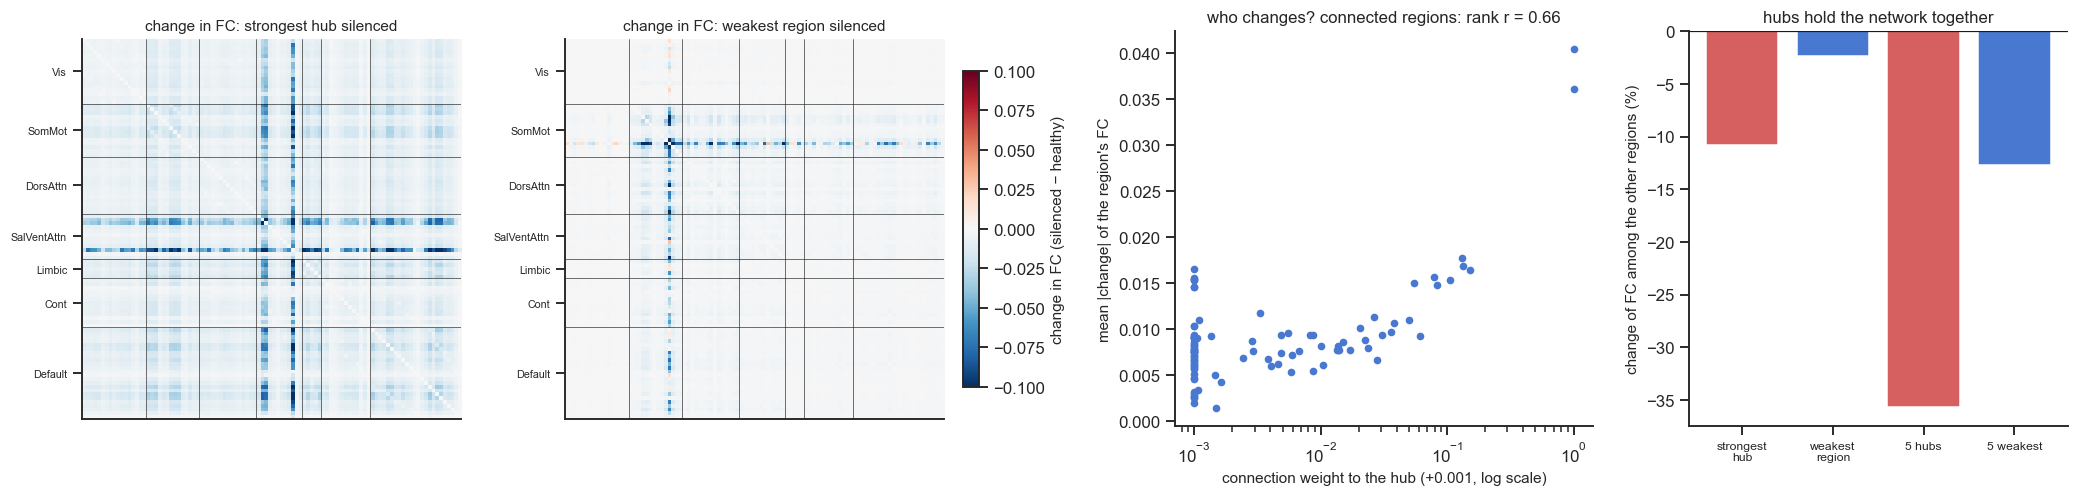

strongest hub  : -11 %
weakest region : -2 %
5 hubs         : -36 %
5 weakest      : -13 %


In [7]:
# @title Solution, steps 2-4: silencing
def silenced_fc(regions):
    a = np.full(100, A0); a[list(regions)] = -5.0
    return model_fc(a)

cases = {"strongest hub": rank[:1], "weakest region": rank[-1:], "5 hubs": rank[:5], "5 weakest": rank[-5:]}
results = {k: silenced_fc(v) for k, v in cases.items()}                 # about 30 s

fig, ax = plt.subplots(1, 4, figsize=(19, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1.1, 1]), layout="constrained")
fig.get_layout_engine().set(w_pad=0.15)
im = show_matrix(ax[0], results["strongest hub"] - base, "change in FC: strongest hub silenced", vmax=0.1)
show_matrix(ax[1], results["weakest region"] - base, "change in FC: weakest region silenced", vmax=0.1)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="change in FC (silenced − healthy)")
k = rank[0]; others = np.setdiff1d(np.arange(100), [k])
change = np.abs((results["strongest hub"] - base)[np.ix_(others, others)]).mean(1)
wk = (sc + sc.T)[k, others]
con = wk > 0                                                            # directly connected regions
rho = np.corrcoef(np.argsort(np.argsort(wk[con])), np.argsort(np.argsort(change[con])))[0, 1]   # rank (Spearman) correlation
ax[2].plot(wk + 1e-3, change, "o", ms=4); ax[2].set_xscale("log")
ax[2].set(xlabel="connection weight to the hub (+0.001, log scale)", ylabel="mean |change| of the region's FC",
          title=f"who changes? connected regions: rank r = {rho:.2f}")
drop = [100 * (fc_among_others(results[c], cases[c]) / fc_among_others(base, cases[c]) - 1) for c in cases]
ax[3].bar(["strongest\nhub", "weakest\nregion", "5 hubs", "5 weakest"], drop, color=["C3", "C0", "C3", "C0"]); ax[3].axhline(0, c="k", lw=0.8)
ax[3].set(ylabel="change of FC among the other regions (%)", title="hubs hold the network together"); ax[3].tick_params(axis="x", labelsize=8)
plt.show()
for c, d in zip(cases, drop): print(f"{c:15s}: {d:+.0f} %")

**Reading the solution.** First two panels: silencing the strongest hub changes many connections **between other regions**, not only
its own row; silencing the weakest region changes almost nothing. Third panel: among the regions wired to the hub, the
stronger the wire, the larger the change (regions not wired to it, at the left, change through indirect paths). Last panel: the FC among the remaining regions drops much more when hubs are silenced. **Hubs hold the
network together**: they relay the correlations between regions that are not directly wired.

<details><summary>Discussion: the answer depends on the model</summary>

Damage to hub regions disrupts FC far beyond the lesion in patients too (Gratton et al. 2012; Aerts et al. 2016). But in
mice, chemogenetic silencing of the prefrontal cortex **increases** FC (Rocchi et al. 2022), as in the slides. The Hopf
model cannot do this: near its working point it is almost linear, and removing a relay can only lower correlations. A
model with bistable regions (NB11) reproduces the increase (Rabuffo et al. 2025). Which laboratory we choose matters.
</details>

## Take-home

* One change, everything else identical (same brain, same noise): the model is a laboratory.
* Silencing a **hub** changes the FC of many other regions; silencing a peripheral region changes almost nothing.
* **Next (NB14b):** instead of silencing a region, we **push** it and follow the push through the connectome.

### Homework
*To do at home, after the class.*
1. **The opposite.** Instead of silencing, push the hub **past** its bifurcation ($a=+0.3$). What happens to the FC
   among the other regions?
2. **Whole networks.** Set $a=-1$ in all regions of the default-mode network. Does the similarity to the measured FC go
   up or down? Compare with NB13b: which regions did myelin put far from the bifurcation?
3. **Random choice.** Silence five regions chosen at random, ten times. Where do the hubs fall in this distribution?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Honey CJ, Sporns O (2008). Dynamical consequences of lesions in cortical networks. *Hum Brain Mapp* 29:802–809.
* Gratton C, Nomura EM, Pérez F, D'Esposito M (2012). Focal brain lesions to critical locations cause widespread
  disruption of the modular organization of the brain. *J Cogn Neurosci* 24:1275–1285.
* Rocchi F et al. (2022). Increased fMRI connectivity upon chemogenetic inhibition of the mouse prefrontal cortex.
  *Nat Commun* 13:1056.
* Rabuffo G et al. (2025). Mapping global brain reconfigurations following local targeted manipulations. *PNAS*
  122:e2405706122.
* Aerts H, Fias W, Caeyenberghs K, Marinazzo D (2016). Brain networks under attack: robustness properties and the
  impact of lesions. *Brain* 139:3063–3083.